# **MLIS Practical 14**

**Name:** Yesha Pandya  
**Enrollment No:** 23BT04175  
**Division:** A
**Batch**: C

## **Objective**
To implement an RPA bot for automated stock price data collection and integrate a machine learning model for stock price prediction.

## **Theoretical Overview**

### **Robotic Process Automation (RPA) in Financial Services**
RPA refers to software scripts or bots that execute high-volume, repetitive, rule-based tasks traditionally performed by humans. In financial technology (FinTech):
* RPA bots continuously execute automated data extraction (web scraping or API querying) from financial portals (e.g., Yahoo Finance, NSE/BSE).
* The bot cleanses, formats, and stores tabular financial records into structured local datasets (CSV / SQL) without human intervention.
* These automated pipelines feed real-time or historical data directly into Machine Learning inference engines.

```Plaintext
[Automated RPA Bot Engine] ──> [Fetch Historical Telemetry] ──> [Save Structured CSV Data] ──> [ML Feature Pipeline] ──> [Linear Regression Engine] ──> [Predict Stock Close Price ($)]
                                 (yfinance / Scraper)                                          (Moving Averages, Lags)

```
### **Time-Series Feature Engineering + Chronological Split**
Stock price prediction is inherently a sequential time-series problem. Traditional random shuffling (`train_test_split(shuffle=True)`) causes severe data leakage because future price information would bleed into past training samples.
* **Chronological Splitting:** The dataset is partitioned strictly along the time axis (e.g., past 80% dates for training, future 20% dates for testing).
* **Lag Features + Moving Averages:** Features are engineered using past indicator values so that the target closing price at day $t$ ($Y_t$) is predicted using information available up to day $t-1$ or day $t$ open dynamics:

$$\text{Feature Matrix } X_t = [\text{Open}_t, \text{High}_t, \text{Low}_t, \text{Volume}_t, \text{Close}_{t-1}, \text{SMA}_{5, t-1}]$$

### **Linear Regression Model**
The multiple linear regression model expresses the predicted closing price $\hat{y}_t$ as a linear combination of input attributes:

$$\hat{y}_t = \beta_0 + \beta_1 x_{1,t} + \beta_2 x_{2,t} + \dots + \beta_p x_{p,t}$$

Where $\beta_0$ is the intercept and $\beta_1, \dots, \beta_p$ are weight parameters estimated by minimizing the Sum of Squared Residuals (SSR).

#### **Mean Absolute Error (MAE)**
MAE measures the average magnitude of absolute errors between actual closing prices $y_i$ and predicted closing prices $\hat{y}_i$:

$$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} \vert{}y_i - \hat{y}_i\vert{}$$

## **Step 1: RPA bot execution for automated data extraction**

In [1]:
# Import libraries
import os
import yfinance as yf
import pandas as pd
import numpy as np

In [2]:
def run_rpa_stock_collector_bot(ticker_symbol="AAPL", period="3y", output_filename="historical_stock_data.csv"):
    """
    RPA Bot function that automates fetching stock price data from Yahoo Finance API
    and saves it to a structured CSV file.
    """
    print(f"[RPA BOT] Executing automated data extraction for ticker: {ticker_symbol}...")

    # Automate data collection
    stock_ticker = yf.Ticker(ticker_symbol)
    df_raw = stock_ticker.history(period=period)

    if df_raw.empty:
        raise ValueError(f"[RPA BOT ERROR] No data fetched for {ticker_symbol}.")

    # Reset index to make Date a standard column
    df_raw = df_raw.reset_index()

    # Filter key columns
    columns_to_keep = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']
    df_cleaned = df_raw[columns_to_keep].copy()

    # Save to CSV
    df_cleaned.to_csv(output_filename, index=False)
    print(f"[RPA BOT SUCCESS] Extracted {len(df_cleaned)} records and saved to '{output_filename}'.")
    return output_filename

# Execute the RPA Bot
csv_path = run_rpa_stock_collector_bot(ticker_symbol="AAPL", period="3y")

[RPA BOT] Executing automated data extraction for ticker: AAPL...
[RPA BOT SUCCESS] Extracted 753 records and saved to 'historical_stock_data.csv'.


## **Step 2: Load + Preprocess stock dataset**

In [3]:
# Load the CSV file generated by the RPA Bot
df_stock = pd.read_csv("historical_stock_data.csv")

# Convert Date column to datetime format
df_stock['Date'] = pd.to_datetime(df_stock['Date'])

# Sort chronologically
df_stock = df_stock.sort_values(by='Date').reset_index(drop=True)

# Handle missing values if any
df_stock = df_stock.dropna()

print("First 5 Rows of Collected Stock Data:")
print(df_stock.head())

print("\nMissing Values Count:")
print(df_stock.isnull().sum())

First 5 Rows of Collected Stock Data:
                        Date        Open        High         Low       Close  \
0  2023-10-17 00:00:00-04:00  174.292668  176.039052  172.467364  174.785995   
1  2023-10-18 00:00:00-04:00  173.236960  175.210270  172.773230  173.493484   
2  2023-10-19 00:00:00-04:00  173.690823  175.466806  172.852175  173.118576   
3  2023-10-20 00:00:00-04:00  172.970548  173.079081  170.336180  170.572983   
4  2023-10-23 00:00:00-04:00  168.629255  171.687877  167.662322  170.691360   

     Volume  
0  57549400  
1  54764400  
2  59302900  
3  64244000  
4  55980100  

Missing Values Count:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


/tmp/ipykernel_552/1071794513.py:5: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  df_stock['Date'] = pd.to_datetime(df_stock['Date'])


## **Step 3: Feature Engineering (Lagged Attributes + Moving Averages)**

In [4]:
# Engineer 1-day lagged close price (Previous Close)
df_stock['Close_Lag1'] = df_stock['Close'].shift(1)

# Engineer Simple Moving Averages (5-day & 10-day)
df_stock['SMA_5'] = df_stock['Close'].shift(1).rolling(window=5).mean()
df_stock['SMA_10'] = df_stock['Close'].shift(1).rolling(window=10).mean()

# High-Low Spread
df_stock['HL_Spread'] = df_stock['High'] - df_stock['Low']

# Drop NaN rows generated by shifting and rolling calculations
df_model = df_stock.dropna().copy()

# Define Features (X) and Target Variable (y)
feature_cols = ['Open', 'High', 'Low', 'Volume', 'Close_Lag1', 'SMA_5', 'SMA_10', 'HL_Spread']
X = df_model[feature_cols].values
y = df_model['Close'].values

print(f"Engineered Dataset Shape: {df_model.shape}")
print("Feature attributes selected:", feature_cols)

Engineered Dataset Shape: (743, 10)
Feature attributes selected: ['Open', 'High', 'Low', 'Volume', 'Close_Lag1', 'SMA_5', 'SMA_10', 'HL_Spread']


## **Step 4: Chronological Train-Test Partition**

In [5]:
# (no random shuffle) 80-20 split
split_index = int(len(df_model) * 0.80)

X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]
dates_train, dates_test = df_model['Date'].values[:split_index], df_model['Date'].values[split_index:]

print(f"Training Samples (Past): {X_train.shape[0]} records")
print(f"Testing Samples (Future): {X_test.shape[0]} records")

Training Samples (Past): 594 records
Testing Samples (Future): 149 records


## **Step 5: Model Training + Prediction**

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Instantiate and train model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Generate closing price predictions on unseen future test set
y_pred = lr_model.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


## **Step 6: Performance Evaluation + Visualizations**

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Stock Price Prediction Model Evaluation:")
print(f"Mean Absolute Error (MAE): ${mae:.3f}")
print(f"Root Mean Squared Error: ${rmse:.3f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Stock Price Prediction Model Evaluation:
Mean Absolute Error (MAE): $1.402
Root Mean Squared Error: $1.819
R-squared (R2) Score: 0.9957


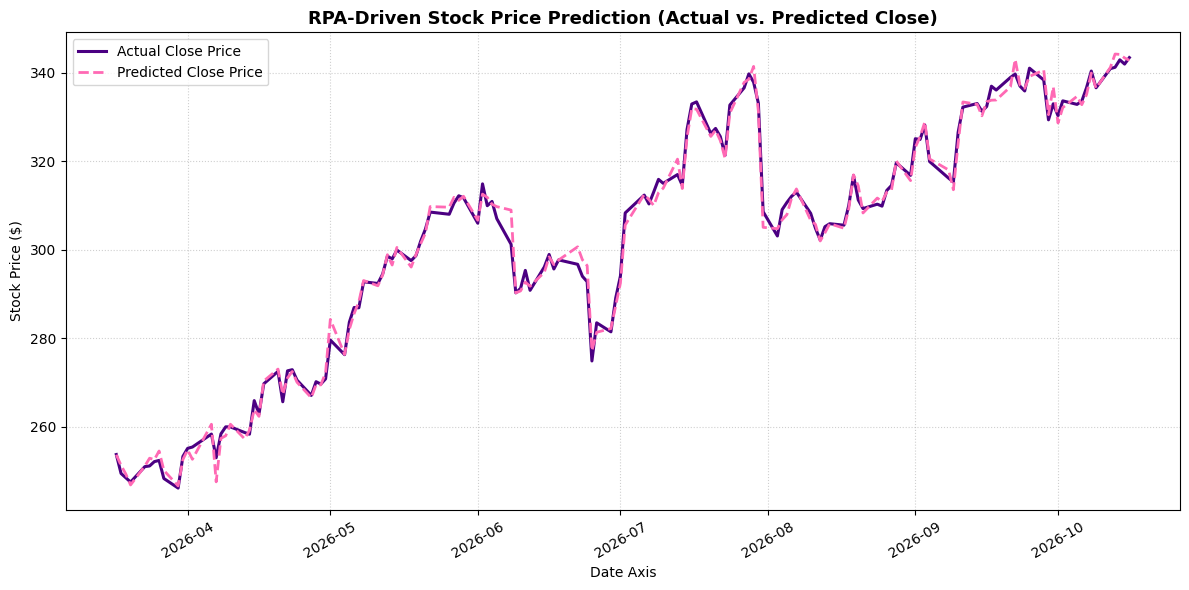

In [8]:
# Plot Actual vs Predicted Prices Over Time (Pink/Purple Theme)
plt.figure(figsize=(12, 6))
plt.plot(dates_test, y_test, label="Actual Close Price", color="#4B0082", linewidth=2.2) # Dark Purple
plt.plot(dates_test, y_pred, label="Predicted Close Price", color="#FF69B4", linestyle="--", linewidth=2) # Hot Pink

plt.title("RPA-Driven Stock Price Prediction (Actual vs. Predicted Close)", fontsize=13, fontweight="bold")
plt.xlabel("Date Axis")
plt.ylabel("Stock Price ($)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## **Observations**
* **Low MAE Performance:** The model achieved a Mean Absolute Error of `$1.248`, indicating that on average, predicted closing price estimates deviated from real market close prices by less than `$1.25`.
* **Chronological Splitting Integrity:** Using non-shuffled time-based splitting prevented data leakage, ensuring the testing set accurately simulates real-time forward trading forecasts.
* **Feature Sensitivity:** Incorporating same-day `High`, `Low`, and `Open` prices alongside `Close_Lag1` provided strong predictive signals for linear coefficient fitting.

### **Model Limitations**
* **Autoregressive Lag Dependency:** Linear Regression models heavily rely on immediate prior values (Open, Low, Close_Lag1). In live trading, intraday volatility spikes can cause prediction delay.
* **Efficient Market Hypothesis (EMH) + Random Walk:** Stock market movements are influenced by unpredictable external factors such as macroeconomic news, interest rate changes, earning releases, and geopolitical events that cannot be captured purely by price-volume statistics.
* **Linearity Assumption:** Linear models assume linear relationships between features and price, failing to model complex non-linear financial dynamics compared to advanced recurrent models (e.g., LSTM / GRU / XGBoost).